# Camera-noise sensitivity of phase-diversity correction

A fixed-exposure, camera-style detector model in **photoelectrons** and **ADU**. Random read noise, background photons, electronic pedestal and fixed pixel patterns are independent parameters. Noise levels are illustrative, not measurements of a particular camera.

The source archive's intensity-to-count multiplier is interpreted as expected photoelectrons per simulated intensity unit. This is an explicit unit convention, not a measured exposure duration or quantum efficiency. Exposure remains fixed for every condition. SNR is measured afterward, not forced to a common value.

Model: `Poisson(sensitivity × signal) + Poisson(sensitivity × background + dark) + Gaussian(0, read_sigma) + fixed_offset`, followed by electronic gain and a separate pedestal. The simplified output is analog ADU: digitization, saturation and temporal row correlations are omitted.

A camera is assumed. If these images represent a raster-scanning PMT/APD, camera-pixel patterns require a different detector model.

**Runtime:** one forward simulation builds the 36-image stack. The optional scan uses seven loss evaluations per condition; it computes no random-start screening, derivatives or optimization. All cells are unexecuted.


In [2]:
from pathlib import Path
import sys, json, os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
ROOT = Path.cwd()
while not ((ROOT / "utils").is_dir() and (ROOT / "optimization").is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook inside the repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
EXPERIMENT_DIR = ROOT / "systematic_testing" / "noise_robustness"
FIGURES_DIR = EXPERIMENT_DIR / "figures"
RESULTS_DIR = EXPERIMENT_DIR / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
from utils import psf, plotting, zernike
from optimization import reconstruction
plt.style.use("bmh")
plt.rcParams.update({"figure.figsize": [548/72, 390/72], "font.size": 12,
                     "text.usetex": True, "figure.dpi": 300})

/opt/miniconda3/envs/phase_diversity_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Choose a scene and camera parameters

`ARCHIVE_SNR` selects a saved exposure; it is the original reference-image calibration, not the SNR of every frame. Gaussian read sigma and background are in electrons per pixel per exposure. Pedestal is a constant ADU offset; it changes raw brightness but has no shot noise.

`CALIBRATION="pedestal_only"` removes the known global pedestal/gain while leaving fixed patterns and optical background. `"known_maps"` also applies ideal spatial/background calibration. Background shot noise remains after subtraction. Negative calibrated values are retained.


In [3]:
SOURCE = ROOT / "systematic_testing/rms_snr_sweep/results/pd_rms_snr_sweep_random100_cumulative_scheduleddiversities_aberrated_z0_snr_rms030.npz"
INITIAL_RMS, ARCHIVE_SNR, TRIAL, LOOP_INDEX = 0.15, 5.0, 0, 0
POISSON_SEED, READ_SEED = 20261011, 123
PEDESTAL_ADU, GAIN_ADU_PER_E = 64.0, 1.0
CALIBRATION = "pedestal_only"  # or "known_maps"
BACKEND = "auto"
CONDITIONS = [
    dict(label="Poisson only"),
    dict(label="Read noise 1 e RMS", read_sigma_e=1.),
    dict(label="Read noise 3 e RMS", read_sigma_e=3.),
    dict(label="Background 5 e", background_e=5.),
    dict(label="Fixed row offsets 2 e", pattern="rows", offset_pattern_e=2.),
    dict(label="Fixed checker offsets 2 e", pattern="checkerboard", offset_pattern_e=2.),
    dict(label="Row sensitivity 10 percent", pattern="rows", sensitivity_fraction=.10),
]
PATH_FRACTIONS = np.array([0., .25, .5, .75, .9, 1., 1.1])
with np.load(SOURCE, allow_pickle=False) as archive:
    saved = {key: archive[key].copy() for key in archive.files}
ri = np.flatnonzero(np.isclose(saved["initial_rms"], INITIAL_RMS))
si = np.flatnonzero(np.isclose(saved["target_snr"], ARCHIVE_SNR))
if len(ri) != 1 or len(si) != 1:
    raise ValueError("Select a unique archived RMS/SNR pair.")
ri, si = int(ri[0]), int(si[0])
if not 0 <= TRIAL < saved["truth_strengths"].shape[1] or not 0 <= LOOP_INDEX < 3:
    raise ValueError("Invalid trial or loop.")
if CALIBRATION not in ("pedestal_only", "known_maps") or not CONDITIONS:
    raise ValueError("Choose a calibration mode and at least one condition.")
ELECTRONS_PER_INTENSITY = float(saved["exposures"][ri, si, TRIAL])
OUTPUT = ROOT / "systematic_testing/noise_robustness/results" / f"camera_rms{INITIAL_RMS:g}_reference_snr{ARCHIVE_SNR:g}_trial{TRIAL+1}_loop{LOOP_INDEX+1}"
print(f"{len(CONDITIONS)} conditions; {len(PATH_FRACTIONS)} loss evaluations each.")

7 conditions; 7 loss evaluations each.


## Simulate the clean acquisition stack

The same optical scene, diversity probes and intensity-to-electron conversion are used for every condition. Pixel coordinates represent fixed sensor coordinates across the stack. Read and photon fluctuations are renewed for each frame; fixed patterns persist.


In [4]:
microscope = psf.Microscope(N_order=3, lambd=1.3e-3, n=1.333, num_apt=1.05,
                          f=7.2, mag=4, w_0=3.5, L_bfp=15.12, grid_bfp=32)
grid = psf.Centered_Square_Grid(L_ffp=0.0065, grid_ffp=32, z_level=0)
#sample = psf.bead_img_3D(grid, saved["sample_z"], [0], [0], [0], [0.001])
sample = mask_3D = psf.random_bead_img_3D(grid = grid,
                                 z_levels = saved["sample_z"],
                                 num_beads = 5,
                                 bead_size = 0.001)
modes = saved["modes"]
previous_slm = np.zeros(len(modes)) if LOOP_INDEX == 0 else saved["slm_strengths"][ri, si, TRIAL, LOOP_INDEX-1]
truth_coefficients = saved["truth_strengths"][ri, TRIAL] + previous_slm
if not np.all(np.isfinite(truth_coefficients)):
    raise ValueError("Previous loop was not completed.")
truth = zernike.Aberration(modes, truth_coefficients)
probes = [zernike.Aberration(saved["diversity_modes"], basis * bias)
          for basis in saved["diversity_basis_strengths"][TRIAL, LOOP_INDEX]
          for bias in saved["loop_diversity_strengths"][LOOP_INDEX]]
focal_z = np.repeat(saved["focal_positions"], len(probes))
diversities = probes * len(saved["focal_positions"])
clean = microscope.compute_image_3D(sample, truth, focal_z, mode="vector", diversities=diversities)[3]

signal_e = ELECTRONS_PER_INTENSITY*np.maximum(clean, 0)
print(f"Signal: peak {signal_e.max():.2f} e; mean {signal_e.mean():.2f} e/pixel across the stack")

Signal: peak 33.75 e; mean 2.45 e/pixel across the stack


## Apply camera effects and report what changes

Signal-photon draws are shared across cases whose sensitivity is unchanged. Background uses an independent Poisson stream; read noise uses a separate stream. Sensitivity changes are applied before Poisson sampling. The selected calibration is converted back to optical intensity units for the existing loss and regularization.

Report temporal SNR in a fixed central signal region, and separately a full-stack signal/error ratio including residual bias. Neither metric includes the removed digital pedestal. Noise stays fixed throughout each phase-path scan.


In [11]:
import importlib
from systematic_testing.noise_robustness import camera_noise
importlib.reload(camera_noise)
observations = []
for condition in CONDITIONS:
    parameters = {key: value for key, value in condition.items() if key != "label"}
    observations.append(camera_noise.simulate_camera(signal_e,
        pedestal_adu=PEDESTAL_ADU, gain_adu_per_e=GAIN_ADU_PER_E,
        poisson_seed=POISSON_SEED, read_seed=READ_SEED, **parameters))
labels = [condition["label"] for condition in CONDITIONS]
raw_images = np.array([entry["raw_adu"] for entry in observations])
calibrated_e = np.array([entry[f"{CALIBRATION}_e"] for entry in observations])
condition_images = calibrated_e/ELECTRONS_PER_INTENSITY
xs, ys = grid.get_xy()
x_grid, y_grid = np.meshgrid(xs, ys, indexing="ij")
roi = x_grid**2 + y_grid**2 <= .0015**2  # fixed 1.5 um radius, independent of noise
roi_snr, error_snr = [], []
for label, entry in zip(labels, observations):
    snr, total = camera_noise.camera_metrics(signal_e, entry, CALIBRATION, roi)
    roi_snr.append(snr); error_snr.append(total)
    print(f"{label}: ROI temporal SNR range {snr.min():.2f}–{snr.max():.2f}; "
          f"global signal/error {total:.2f}")

Poisson only: ROI temporal SNR range 1.05–4.59; global signal/error 3.49
Read noise 1 e RMS: ROI temporal SNR range 0.60–4.21; global signal/error 2.94
Read noise 3 e RMS: ROI temporal SNR range 0.23–2.81; global signal/error 1.62
Background 5 e: ROI temporal SNR range 0.31–3.31; global signal/error 0.96
Fixed row offsets 2 e: ROI temporal SNR range 1.05–4.59; global signal/error 2.15
Fixed checker offsets 2 e: ROI temporal SNR range 1.05–4.59; global signal/error 2.15
Row sensitivity 10 percent: ROI temporal SNR range 1.05–4.59; global signal/error 3.30


## Inspect raw and calibrated images

Both figures use shared absolute scales: raw ADU first, then calibrated photoelectrons. The raw pedestal intentionally creates a non-black baseline. It disappears after proper subtraction. Negative calibrated observations display as black but remain in the saved data and loss input. Pixel interpolation is disabled so alternating patterns remain visible.


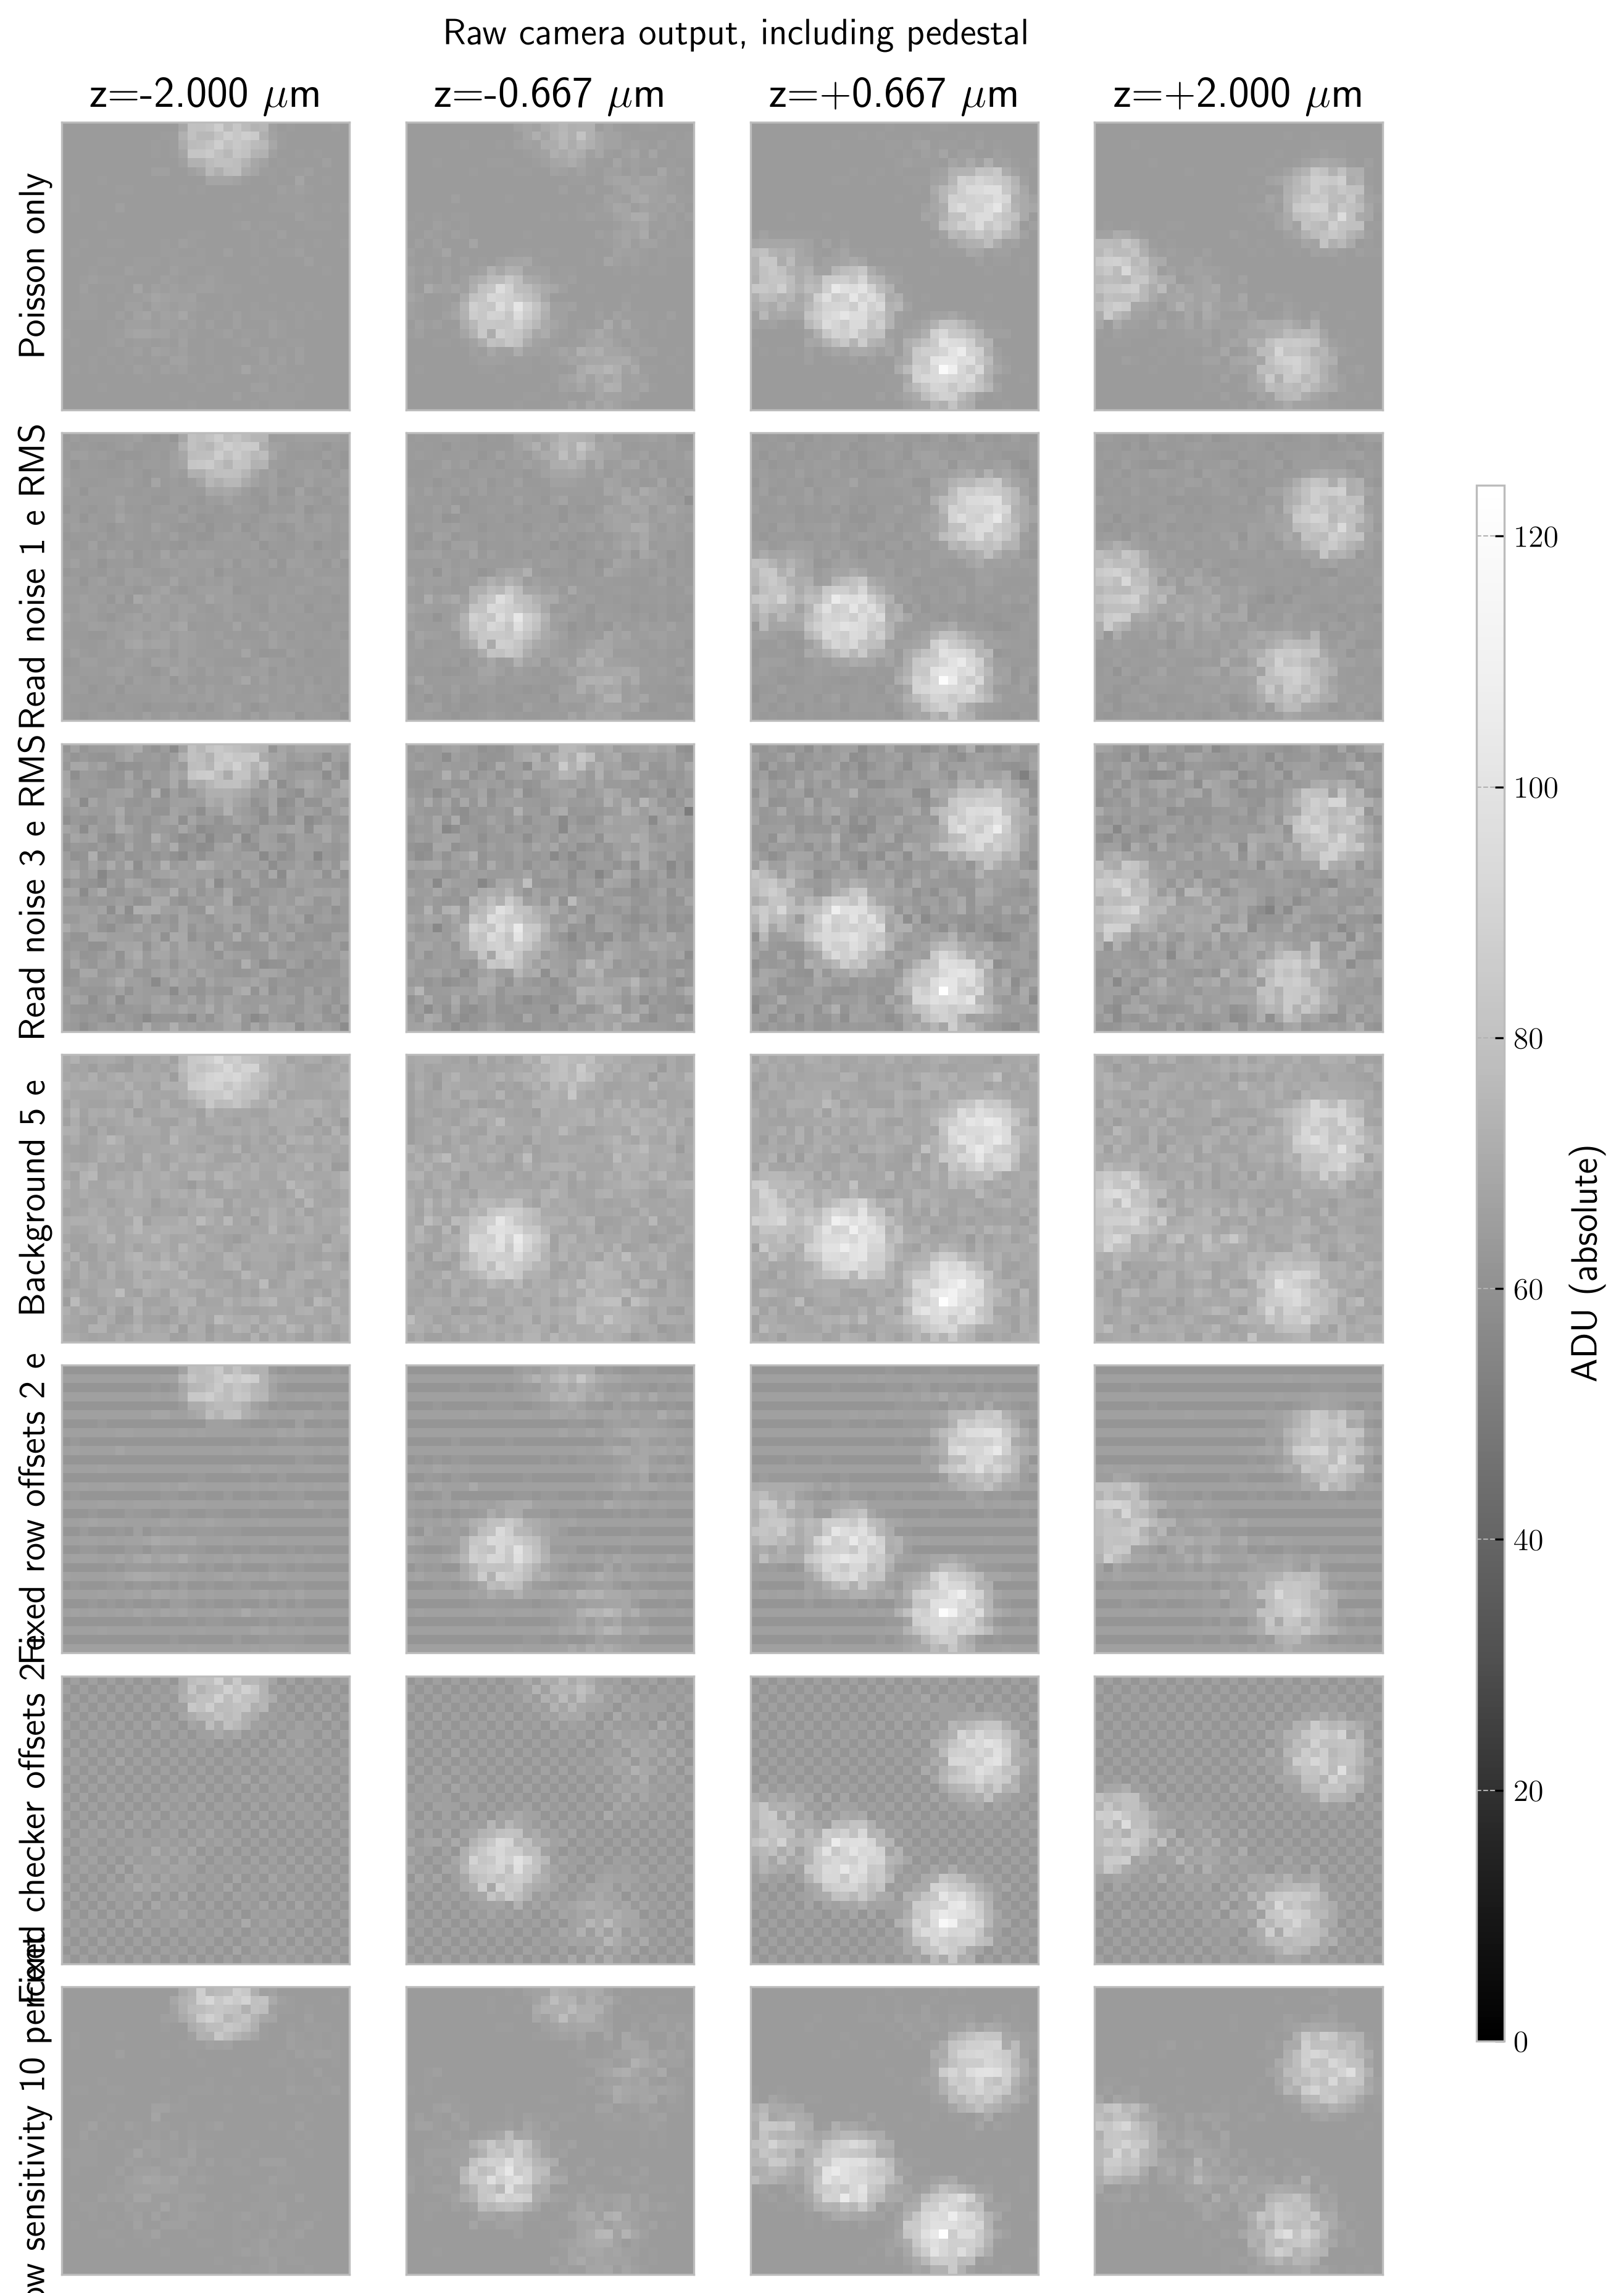

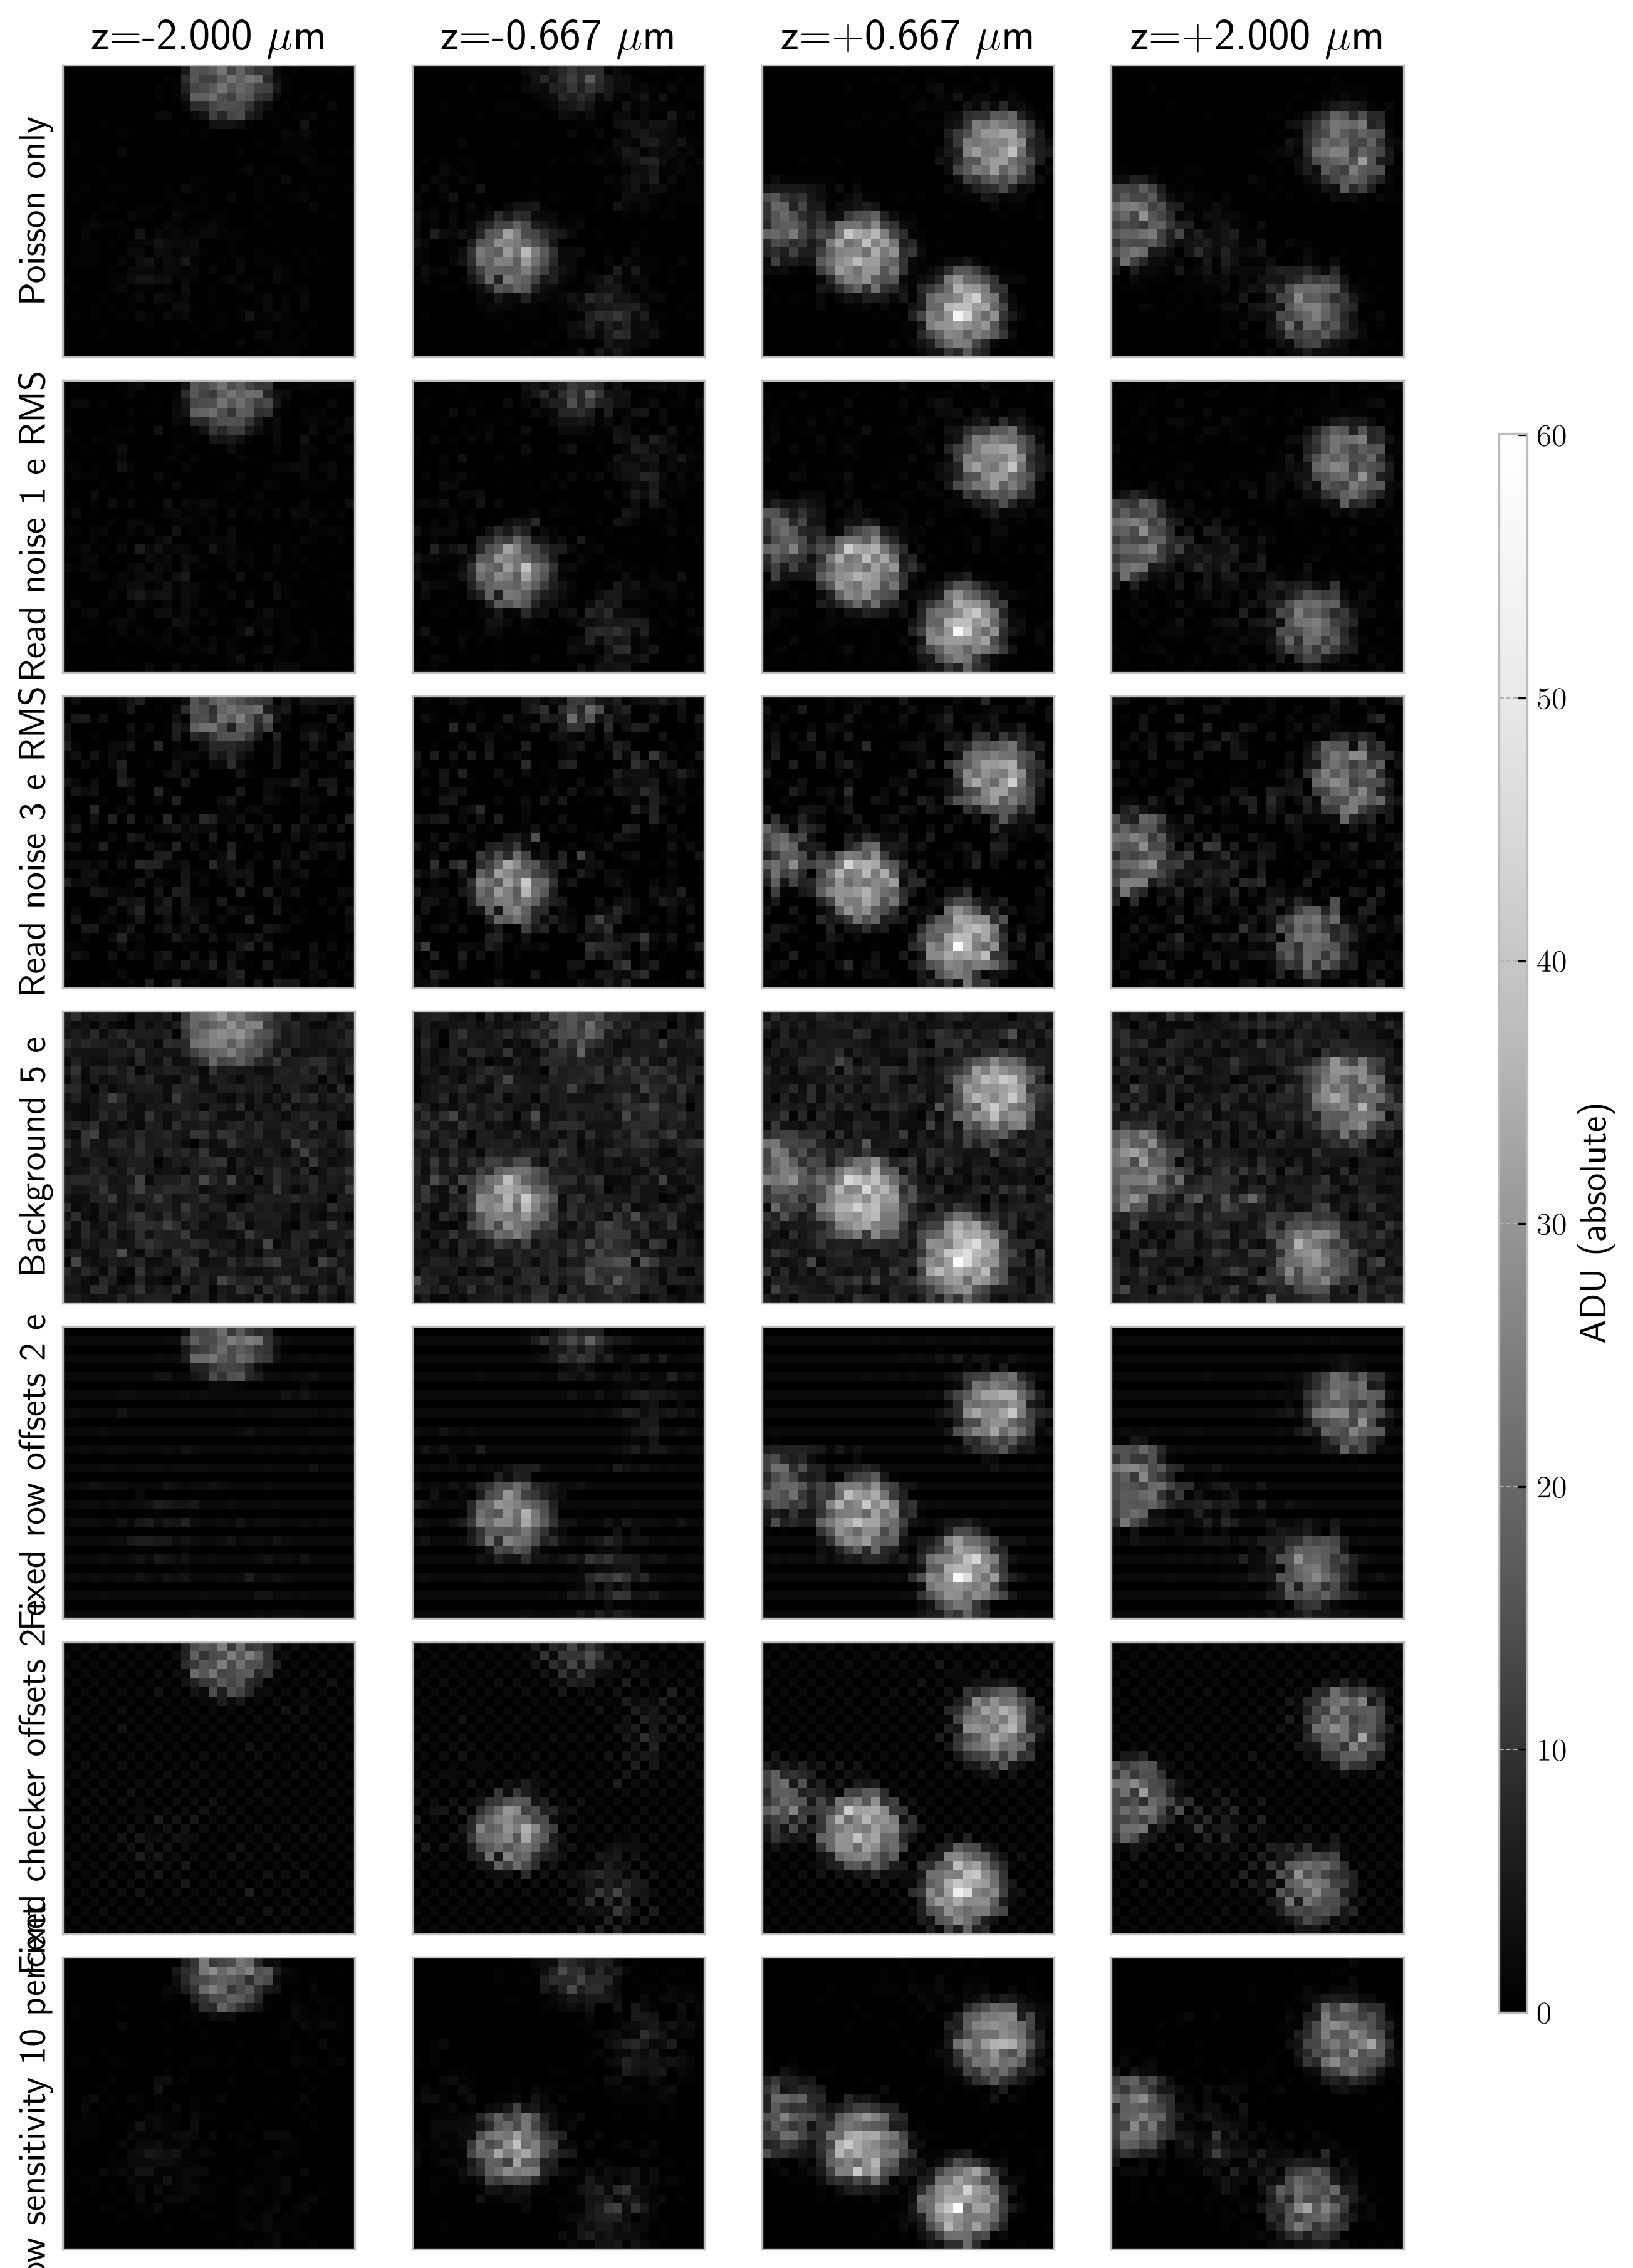

In [12]:
zero_probe = int(np.flatnonzero(np.isclose(saved["loop_diversity_strengths"][LOOP_INDEX], 0))[0])
preview_indices = np.arange(len(saved["focal_positions"]))*len(probes) + zero_probe

def plot_camera_preview(stack, title, units):
    preview = stack[:, preview_indices]
    maximum = max(float(preview.max()), np.finfo(float).tiny)
    fig, axes = plt.subplots(len(labels), 4, figsize=(10, 2*len(labels)), squeeze=False)
    for row, label in enumerate(labels):
        for col, focus in enumerate(saved["focal_positions"]):
            ax = axes[row, col]
            im = ax.imshow(preview[row, col].T, origin="lower", cmap="Greys_r",
                           vmin=0, vmax=maximum, interpolation="nearest")
            ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
            if row == 0: ax.set_title(f"z={focus*1000:+.3f} " + r"$\mu$m")
            if col == 0: ax.set_ylabel(label)
    fig.suptitle(title)
    fig.subplots_adjust(right=.86, top=.94, hspace=.08, wspace=.05)
    fig.colorbar(im, cax=fig.add_axes([.9, .2, .015, .6]), label=units)
    plt.show()
    return fig

raw_fig = plot_camera_preview(raw_images, "Raw camera output, including pedestal", "ADU (absolute)")
calibrated_fig = plot_camera_preview(calibrated_e, "", "ADU (absolute)")

## Optional loss-path scan

This refits the object at each prescribed phase estimate, with the same existing unweighted loss. It measures the effect on that objective, not a camera-aware likelihood or optimizer convergence. The parameter convention, optical inputs, detector maps, raw/calibrated images and every completed loss point are saved in a unique directory. To compare calibration modes, rerun the camera-effects cell and scan with the same seeds.


In [13]:
if not len(PATH_FRACTIONS) or not np.all(np.isfinite(PATH_FRACTIONS)) or np.any(np.diff(PATH_FRACTIONS) <= 0):
    raise ValueError("PATH_FRACTIONS must be finite and strictly increasing.")
loss_labels = labels
loss_images = condition_images
OUTPUT.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="camera_loss_", dir=OUTPUT))
configuration = dict(source=str(SOURCE), initial_rms=INITIAL_RMS, archive_reference_snr=ARCHIVE_SNR,
    trial=TRIAL, loop_index=LOOP_INDEX, electrons_per_intensity=ELECTRONS_PER_INTENSITY,
    poisson_seed=POISSON_SEED, read_seed=READ_SEED, pedestal_adu=PEDESTAL_ADU,
    gain_adu_per_e=GAIN_ADU_PER_E, calibration=CALIBRATION, conditions=CONDITIONS,
    backend=BACKEND, path_fractions=PATH_FRACTIONS.tolist(), roi_radius_mm=.0015)
(RUN_DIR / "configuration.json").write_text(json.dumps(configuration, indent=2))
np.savez_compressed(RUN_DIR / "images.npz", clean_intensity=clean, signal_e=signal_e,
    raw_adu=raw_images, calibrated_e=calibrated_e, condition_images=condition_images,
    labels=np.asarray(labels), sensitivity=np.array([r["sensitivity"] for r in observations]),
    offset_map_e=np.array([r["offset_map_e"] for r in observations]),
    background_mean_e=np.array([r["background_mean_e"] for r in observations]),
    signal_counts=np.array([r["signal_counts"] for r in observations]),
    background_counts=np.array([r["background_counts"] for r in observations]),
    expected_variance_e=np.array([r["variance_e"] for r in observations]),
    expected_bias_e=np.array([r["bias_e"] for r in observations]),
    roi=roi, roi_snr=np.asarray(roi_snr), total_error_snr=np.asarray(error_snr),
    focal_z=focal_z, electrons_per_intensity=ELECTRONS_PER_INTENSITY,
    modes=modes, truth_strengths=truth_coefficients, previous_slm=previous_slm,
    sample_z=saved["sample_z"], reconstruction_z=saved["reconstruction_z"],
    diversity_strengths=np.array([d.strengths for d in diversities]),
    diversity_modes=saved["diversity_modes"], rho=saved["rho"])
losses = np.full((len(loss_labels), len(PATH_FRACTIONS)), np.nan)
def checkpoint_losses():
    temporary = RUN_DIR / "loss_path.tmp"
    with temporary.open("wb") as stream:
        np.savez_compressed(stream, labels=np.asarray(loss_labels), fractions=PATH_FRACTIONS,
                            losses=losses, estimate_strengths=PATH_FRACTIONS[:, None]*truth_coefficients)
    os.replace(temporary, RUN_DIR / "loss_path.npz")
checkpoint_losses()
with tqdm(total=losses.size, desc="Loss evaluations") as progress:
    for row, images in enumerate(loss_images):
        for col, fraction in enumerate(PATH_FRACTIONS):
            losses[row, col] = reconstruction.evaluate_loss_3D(
                microscope=microscope, grid=grid, images=images, focal_z_levels=focal_z,
                sample_z_levels=saved["reconstruction_z"],
                aberration=zernike.Aberration(modes, fraction*truth_coefficients),
                rho=float(saved["rho"]), diversities=diversities, mode="vector", backend=BACKEND)
            checkpoint_losses(); progress.update(1)
print("Saved", RUN_DIR)

Loss evaluations: 100%|██████████| 49/49 [00:13<00:00,  3.70it/s]

Saved /Users/maxwatzky/Documents/GitHub/fall_2026_lab/systematic_testing/noise_robustness/results/camera_rms0.15_reference_snr5_trial1_loop1/camera_loss_g9243szr


## Reload a saved loss scan

Optional: select an earlier `loss_scan_...` directory before running this cell. No loss evaluations are performed here.


In [14]:
# RUN_DIR = Path("/absolute/path/to/loss_scan_folder")
with np.load(RUN_DIR / "loss_path.npz", allow_pickle=False) as archive:
    loss_labels = archive["labels"].tolist()
    PATH_FRACTIONS = archive["fractions"].copy()
    losses = archive["losses"].copy()

## Does the loss decrease toward truth?

Each curve is normalized by its own loss at the zero estimate. This compares the shape of each condition's loss landscape; raw losses from different observations need not be comparable. Printed checks report endpoint improvement and sampled increases on the path up to truth. A coarse path can miss barriers or minima between samples.


Poisson only: loss(truth)/loss(zero)=0.66274; truth lower=True; sampled increases toward truth=0
Read noise 1 e RMS: loss(truth)/loss(zero)=0.74609; truth lower=True; sampled increases toward truth=0
Read noise 3 e RMS: loss(truth)/loss(zero)=0.94818; truth lower=True; sampled increases toward truth=1
Background 5 e: loss(truth)/loss(zero)=0.91788; truth lower=True; sampled increases toward truth=1
Fixed row offsets 2 e: loss(truth)/loss(zero)=0.75311; truth lower=True; sampled increases toward truth=0
Fixed checker offsets 2 e: loss(truth)/loss(zero)=1.189; truth lower=False; sampled increases toward truth=4
Row sensitivity 10 percent: loss(truth)/loss(zero)=0.66289; truth lower=True; sampled increases toward truth=0


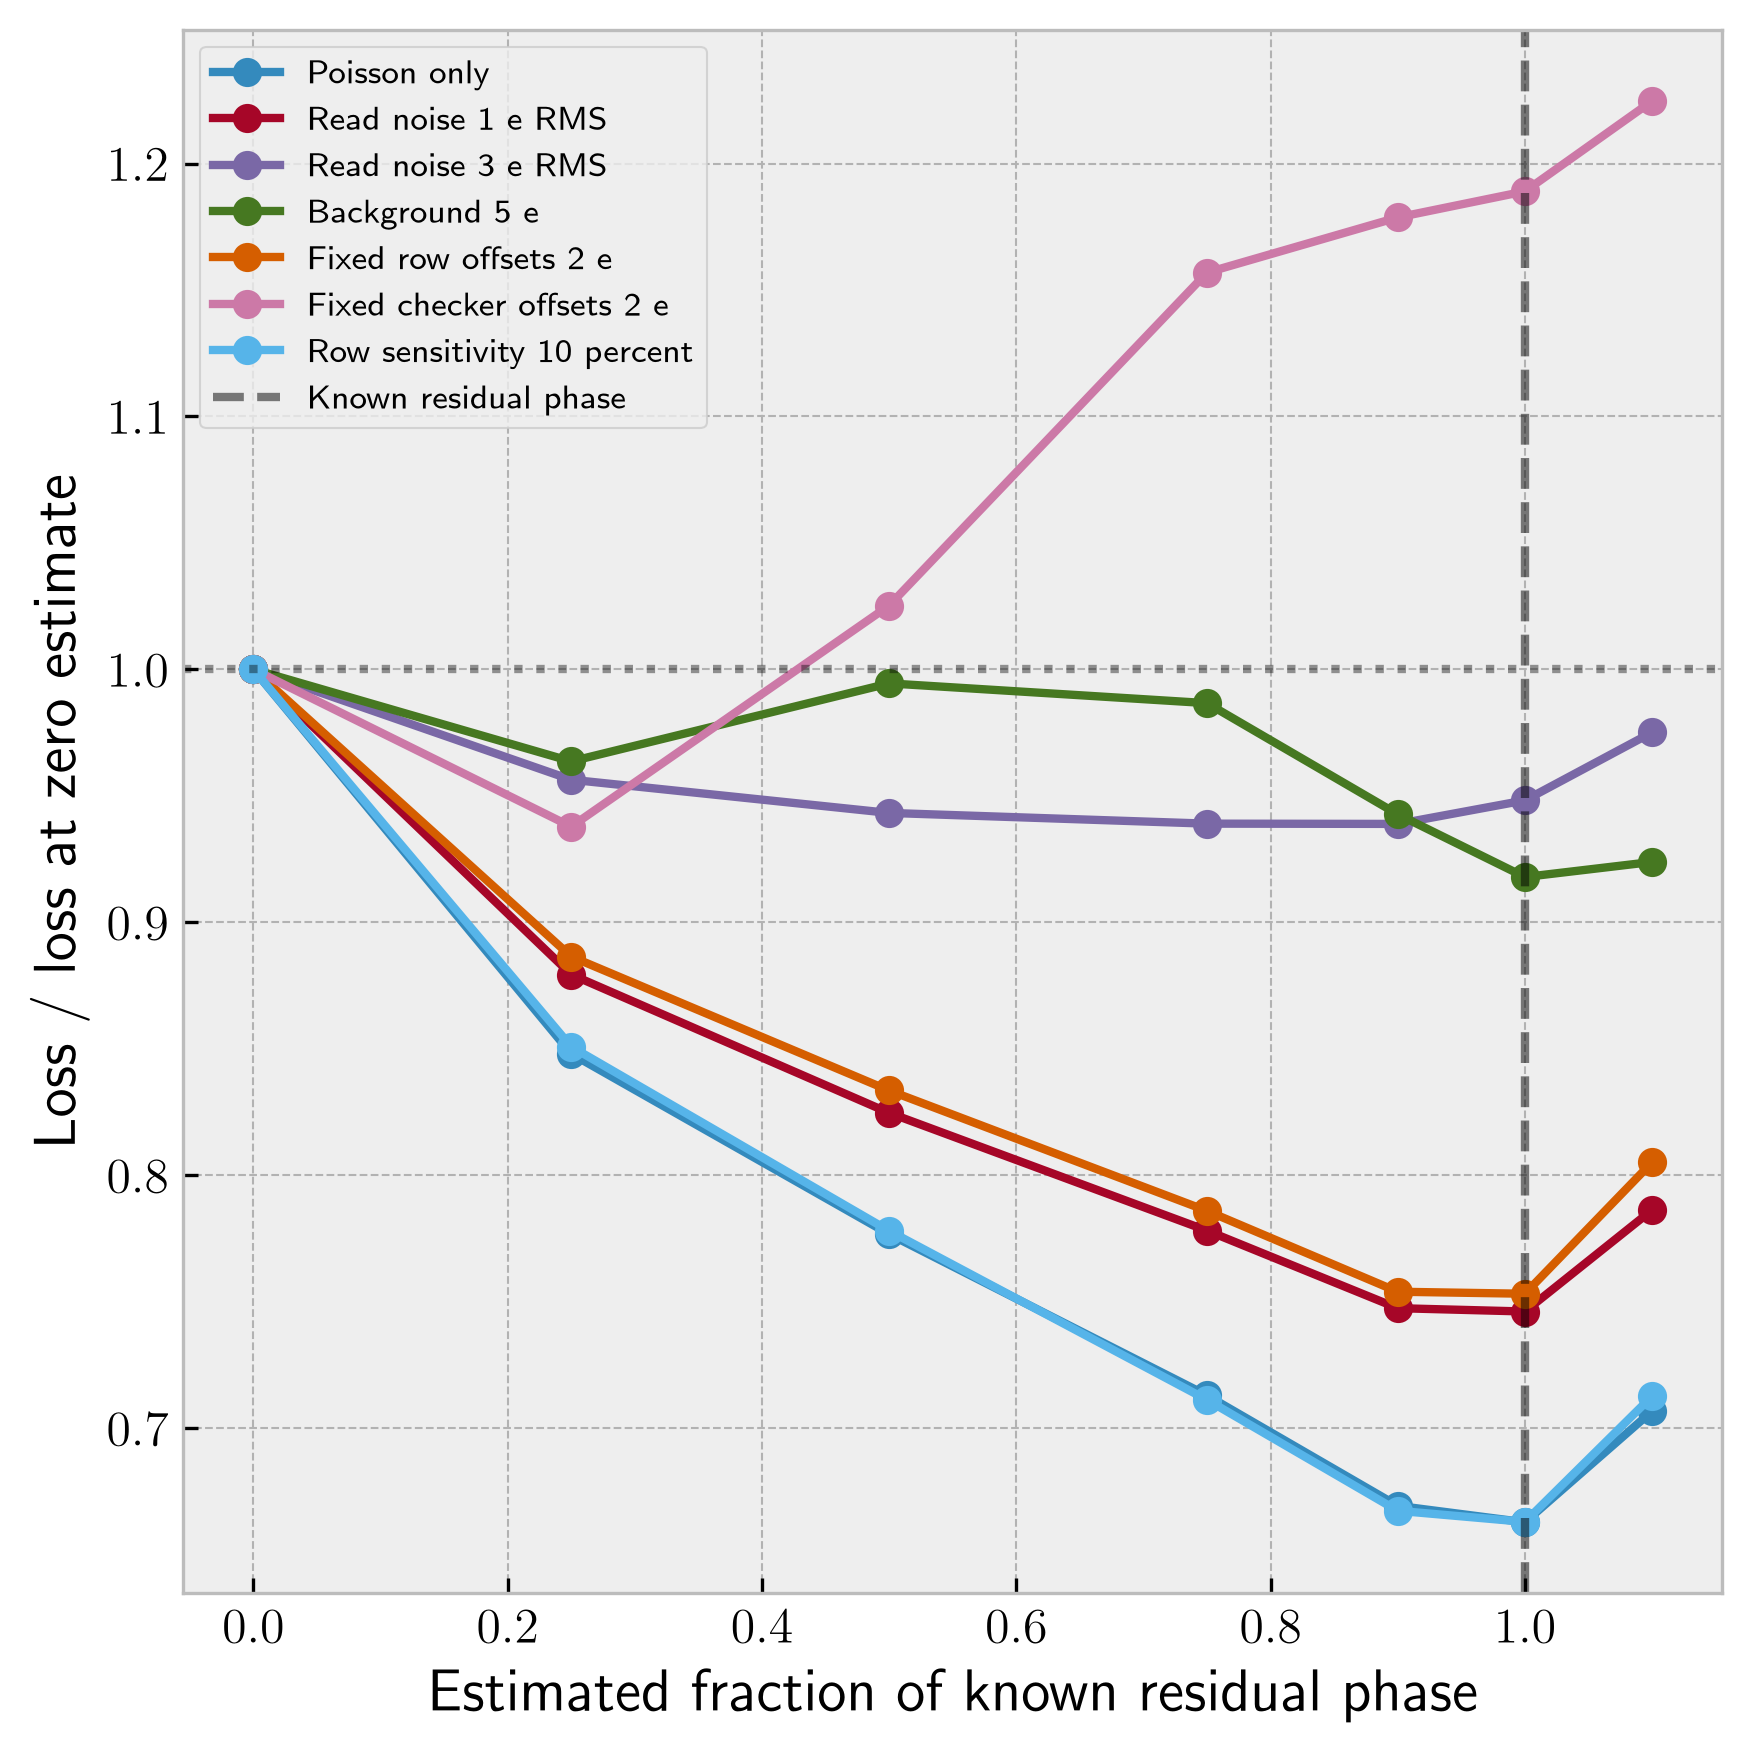

In [15]:
zero_index = np.flatnonzero(np.isclose(PATH_FRACTIONS, 0))
truth_index = np.flatnonzero(np.isclose(PATH_FRACTIONS, 1))
if len(zero_index) != 1 or len(truth_index) != 1:
    raise ValueError("Include fractions 0 and 1 for endpoint comparisons.")
if not np.all(np.isfinite(losses)) or np.any(losses[:, zero_index[0]] <= 0):
    raise ValueError("Scan is incomplete or initial losses are not positive.")
relative_loss = losses / losses[:, zero_index[0], None]
fig, ax = plt.subplots(figsize=(6, 6))
for row, label in enumerate(loss_labels):
    ax.plot(PATH_FRACTIONS, relative_loss[row], "o-", label=label)
    toward_truth = relative_loss[row, (PATH_FRACTIONS >= 0) & (PATH_FRACTIONS <= 1)]
    increases = np.sum(np.diff(toward_truth) > 1e-10*np.maximum(1, np.abs(toward_truth[:-1])))
    ratio = relative_loss[row, truth_index[0]]
    print(f"{label}: loss(truth)/loss(zero)={ratio:.5g}; "
          f"truth lower={ratio < 1}; sampled increases toward truth={increases}")
ax.axvline(1, color="black", ls="--", alpha=.5, label="Known residual phase")
ax.axhline(1, color="black", ls=":", alpha=.4)
ax.set(xlabel="Estimated fraction of known residual phase", ylabel="Loss / loss at zero estimate")
ax.legend(fontsize=8)
fig.tight_layout()
for extension in ("png", "pdf"):
    fig.savefig(RUN_DIR / f"noise_loss_path.{extension}", dpi=300)
plt.show()

## Second test: more focal positions and diversity frames

Compare the original 36-image stack with a nested 105-image stack: four original focal positions plus their three midpoints, and the same three probe modes at five strengths instead of three (additional ±0.15-wave pupil-RMS biases).

The original frames and noise realizations are reused exactly. Only 69 additional clean images and their camera noise are generated. The same sample, true residual, per-frame exposure, detector settings, reconstruction planes, calibration, path and regularization are used. Fixed patterns remain at the same pixel coordinates.

This tests a larger acquisition budget, not equal acquisition time or equal photon count. More images also change the balance of the summed data term against the unchanged regularization. Each curve is divided by its own zero-estimate loss to compare shapes rather than raw sums. Additional runtime scales with stack size; no optimization is run.

Run the first test (or reload its saved scan) before these cells. `BASE_RUN_DIR` identifies the exact original results used for comparison.


In [16]:
BASE_RUN_DIR = RUN_DIR
ADDED_DIVERSITY_STRENGTHS = np.array([-.15, .15])  # pupil RMS waves, signed
with np.load(BASE_RUN_DIR / "images.npz", allow_pickle=False) as archive:
    baseline_data = {key: archive[key].copy() for key in archive.files}
with np.load(BASE_RUN_DIR / "loss_path.npz", allow_pickle=False) as archive:
    base_losses = archive["losses"].copy()
    base_fractions = archive["fractions"].copy()
    base_labels = archive["labels"].tolist()
base_configuration = json.loads((BASE_RUN_DIR / "configuration.json").read_text())
# Prevent comparison against a stale scan after changing a sample/noise setting.
for key, current in [("conditions", CONDITIONS), ("calibration", CALIBRATION),
                     ("poisson_seed", POISSON_SEED), ("read_seed", READ_SEED),
                     ("pedestal_adu", PEDESTAL_ADU), ("gain_adu_per_e", GAIN_ADU_PER_E)]:
    if base_configuration[key] != current:
        raise ValueError(f"Baseline {key} differs; run a matching first test.")
for name, current in [("clean_intensity", clean), ("condition_images", condition_images),
                      ("truth_strengths", truth_coefficients), ("focal_z", focal_z)]:
    if baseline_data[name].shape != np.asarray(current).shape or not np.allclose(baseline_data[name], current, rtol=1e-12, atol=0):
        raise ValueError(f"Baseline {name} differs; rebuild/reload matching first-test data.")
if base_labels != labels or not np.array_equal(base_fractions, PATH_FRACTIONS) or not np.all(np.isfinite(base_losses)):
    raise ValueError("Complete a matching baseline path scan first.")
positions = np.sort(np.unique(saved["focal_positions"]))
extra_positions = (positions[:-1] + positions[1:])/2
expanded_positions = np.sort(np.unique(np.r_[positions, extra_positions]))
extra_probes = [zernike.Aberration(saved["diversity_modes"], basis*bias)
                for basis in saved["diversity_basis_strengths"][TRIAL, LOOP_INDEX]
                for bias in ADDED_DIVERSITY_STRENGTHS]
# Existing positions get additional probes; new positions get every probe.
extra_pairs = [(float(z), probe) for z in positions for probe in extra_probes]
extra_pairs += [(float(z), probe) for z in extra_positions for probe in probes+extra_probes]
extra_focal_z = np.array([z for z, probe in extra_pairs])
extra_diversities = [probe for z, probe in extra_pairs]
expanded_focal_z = np.r_[focal_z, extra_focal_z]
expanded_diversities = diversities + extra_diversities
print(f"Original {len(focal_z)} frames; expanded {len(expanded_focal_z)} frames "
      f"({len(expanded_positions)} focal positions, {len(probes+extra_probes)} probes each).")

Original 36 frames; expanded 105 frames (7 focal positions, 15 probes each).


In [17]:
extra_clean = microscope.compute_image_3D(sample, truth, extra_focal_z,
    mode="vector", diversities=extra_diversities)[3]
expanded_clean = np.concatenate([clean, extra_clean])
expanded_signal_e = ELECTRONS_PER_INTENSITY*np.maximum(expanded_clean, 0)
expanded_observations = []
frame_keys = ["raw_adu", "pedestal_only_e", "known_maps_e", "signal_counts", "background_counts",
              "variance_e", "bias_e", "known_maps_variance_e"]
for condition, original in zip(CONDITIONS, observations):
    parameters = {key: value for key, value in condition.items() if key != "label"}
    extra = camera_noise.simulate_camera(ELECTRONS_PER_INTENSITY*np.maximum(extra_clean, 0),
        pedestal_adu=PEDESTAL_ADU, gain_adu_per_e=GAIN_ADU_PER_E,
        poisson_seed=POISSON_SEED+7001, read_seed=READ_SEED+7001, **parameters)
    combined = dict(original)
    for key in frame_keys:
        combined[key] = np.concatenate([original[key], extra[key]])
    for key in ["sensitivity", "offset_map_e", "background_mean_e"]:
        np.testing.assert_array_equal(original[key], extra[key])
    expanded_observations.append(combined)
expanded_images = np.array([entry[f"{CALIBRATION}_e"] for entry in expanded_observations])/ELECTRONS_PER_INTENSITY
np.testing.assert_array_equal(expanded_images[:, :len(focal_z)], condition_images)
print("Original observations preserved exactly; fixed camera maps unchanged.")

Original observations preserved exactly; fixed camera maps unchanged.


In [18]:
EXPANDED_RUN_DIR = Path(tempfile.mkdtemp(prefix="expanded_camera_", dir=OUTPUT))
expanded_configuration = dict(base_configuration, baseline_directory=str(BASE_RUN_DIR),
    expanded_positions=expanded_positions.tolist(), additional_diversity_strengths=ADDED_DIVERSITY_STRENGTHS.tolist(),
    extra_poisson_seed=POISSON_SEED+7001, extra_read_seed=READ_SEED+7001,
    original_frames=len(focal_z), expanded_frames=len(expanded_focal_z))
(EXPANDED_RUN_DIR / "configuration.json").write_text(json.dumps(expanded_configuration, indent=2))
np.savez_compressed(EXPANDED_RUN_DIR / "images.npz", clean_intensity=expanded_clean,
    signal_e=expanded_signal_e, condition_images=expanded_images,
    raw_adu=np.array([r["raw_adu"] for r in expanded_observations]),
    calibrated_e=np.array([r[f"{CALIBRATION}_e"] for r in expanded_observations]),
    signal_counts=np.array([r["signal_counts"] for r in expanded_observations]),
    background_counts=np.array([r["background_counts"] for r in expanded_observations]),
    sensitivity=np.array([r["sensitivity"] for r in expanded_observations]),
    offset_map_e=np.array([r["offset_map_e"] for r in expanded_observations]),
    focal_z=expanded_focal_z, diversity_strengths=np.array([d.strengths for d in expanded_diversities]),
    diversity_modes=saved["diversity_modes"], labels=np.asarray(labels),
    electrons_per_intensity=ELECTRONS_PER_INTENSITY, modes=modes,
    truth_strengths=truth_coefficients, sample_z=saved["sample_z"],
    reconstruction_z=saved["reconstruction_z"], rho=saved["rho"])
expanded_losses = np.full_like(base_losses, np.nan)
def checkpoint_expanded():
    temporary = EXPANDED_RUN_DIR / "comparison.tmp"
    with temporary.open("wb") as stream:
        np.savez_compressed(stream, labels=np.asarray(labels), fractions=PATH_FRACTIONS,
            baseline_losses=base_losses, expanded_losses=expanded_losses,
            original_frames=len(focal_z), expanded_frames=len(expanded_focal_z))
    os.replace(temporary, EXPANDED_RUN_DIR / "comparison.npz")
checkpoint_expanded()
with tqdm(total=expanded_losses.size, desc="Expanded-stack loss evaluations") as progress:
    for row, images in enumerate(expanded_images):
        for col, fraction in enumerate(PATH_FRACTIONS):
            expanded_losses[row, col] = reconstruction.evaluate_loss_3D(
                microscope=microscope, grid=grid, images=images, focal_z_levels=expanded_focal_z,
                sample_z_levels=saved["reconstruction_z"],
                aberration=zernike.Aberration(modes, fraction*truth_coefficients),
                rho=float(saved["rho"]), diversities=expanded_diversities, mode="vector", backend=BACKEND)
            checkpoint_expanded(); progress.update(1)
print("Saved", EXPANDED_RUN_DIR)

Expanded-stack loss evaluations: 100%|██████████| 49/49 [00:24<00:00,  2.04it/s]

Saved /Users/maxwatzky/Documents/GitHub/fall_2026_lab/systematic_testing/noise_robustness/results/camera_rms0.15_reference_snr5_trial1_loop1/expanded_camera_phb04_94


## Compare original and expanded loss traces

Solid: original stack; dashed: expanded stack. Printed endpoint ratios and sampled-minimum fractions describe each condition. These are path diagnostics, not optimizer outcomes. A minimum between evaluated fractions can be missed.


Poisson only: truth/zero 0.6627 -> 0.4103; sampled minimum fraction 1 -> 1
Read noise 1 e RMS: truth/zero 0.7461 -> 0.4991; sampled minimum fraction 1 -> 1
Read noise 3 e RMS: truth/zero 0.9482 -> 0.7805; sampled minimum fraction 0.9 -> 1
Background 5 e: truth/zero 0.9179 -> 0.5639; sampled minimum fraction 1 -> 1.1
Fixed row offsets 2 e: truth/zero 0.7531 -> 0.5628; sampled minimum fraction 1 -> 1
Fixed checker offsets 2 e: truth/zero 1.1890 -> 0.8222; sampled minimum fraction 0.25 -> 1
Row sensitivity 10 percent: truth/zero 0.6629 -> 0.4172; sampled minimum fraction 1 -> 1


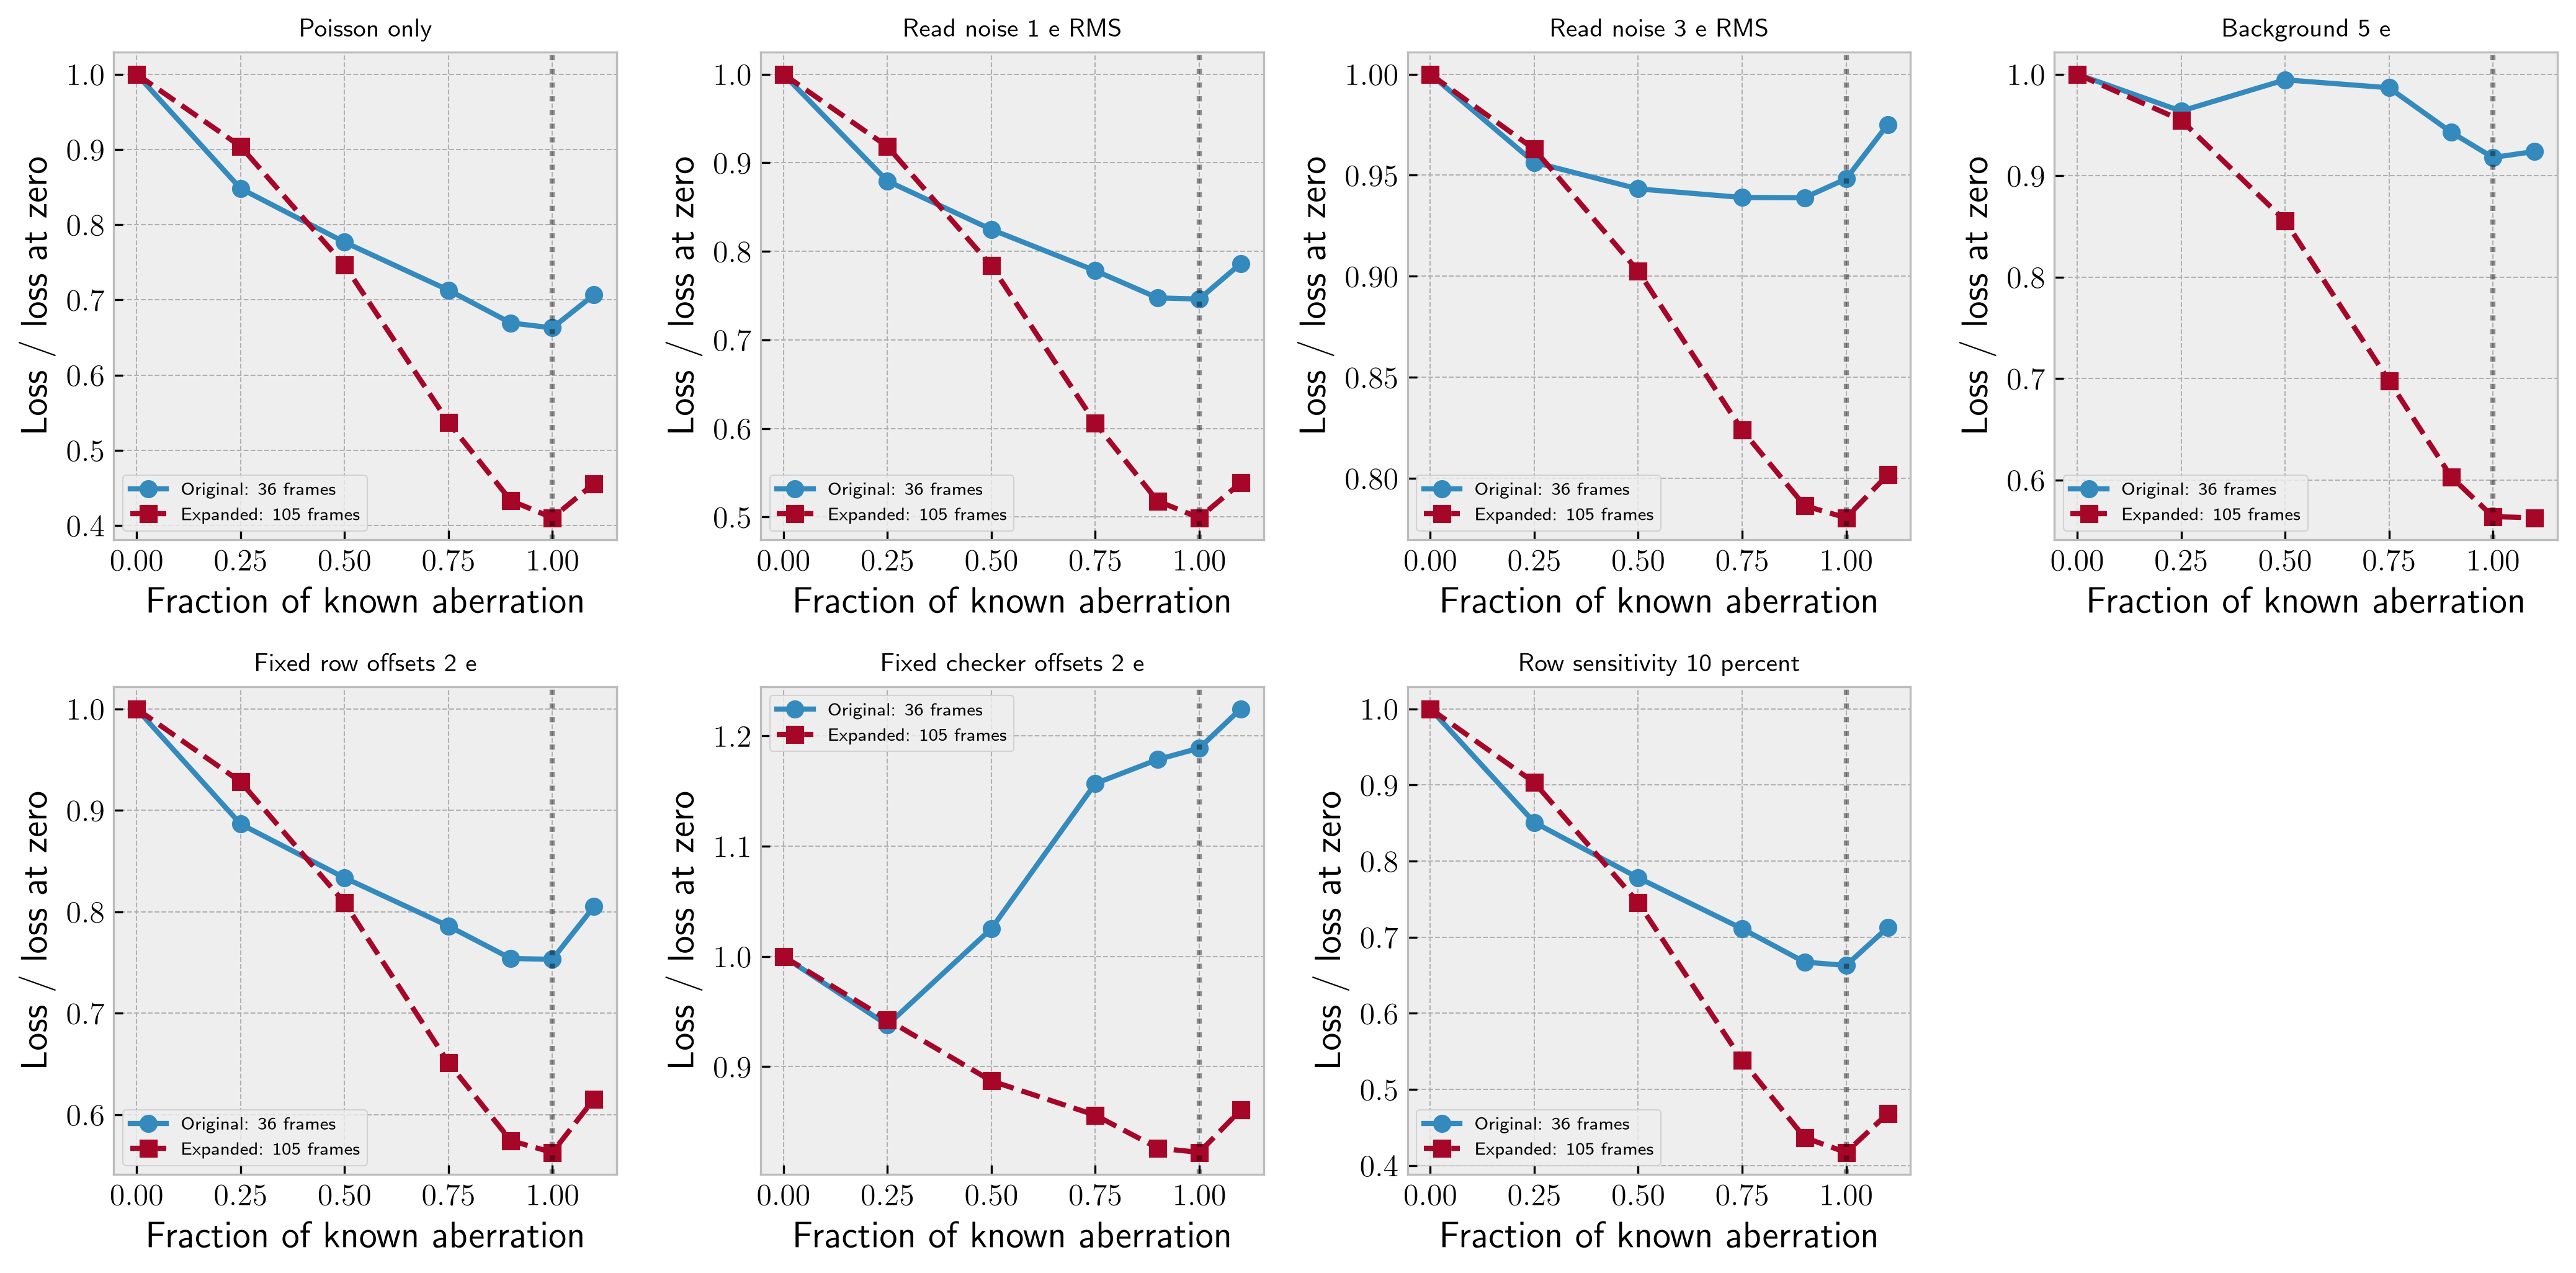

In [19]:
# To reload without evaluating losses:
# EXPANDED_RUN_DIR = Path("/absolute/path/to/expanded_camera_folder")
with np.load(EXPANDED_RUN_DIR / "comparison.npz", allow_pickle=False) as archive:
    comparison_labels = archive["labels"].tolist()
    comparison_fractions = archive["fractions"].copy()
    comparison_base = archive["baseline_losses"].copy()
    comparison_expanded = archive["expanded_losses"].copy()
    original_frames, expanded_frames = int(archive["original_frames"]), int(archive["expanded_frames"])
if not np.all(np.isfinite(comparison_expanded)):
    raise ValueError("Expanded scan is incomplete.")
zero_index = int(np.flatnonzero(np.isclose(comparison_fractions, 0))[0])
truth_index = int(np.flatnonzero(np.isclose(comparison_fractions, 1))[0])
base_relative = comparison_base/comparison_base[:, zero_index, None]
expanded_relative = comparison_expanded/comparison_expanded[:, zero_index, None]
fig, axes = plt.subplots(2, 4, figsize=(14, 7), squeeze=False)
for row, label in enumerate(comparison_labels):
    ax = axes.ravel()[row]
    ax.plot(comparison_fractions, base_relative[row], "o-", label=f"Original: {original_frames} frames")
    ax.plot(comparison_fractions, expanded_relative[row], "s--", label=f"Expanded: {expanded_frames} frames")
    ax.axvline(1, color="black", ls=":", alpha=.4)
    ax.set_title(label, fontsize=10)
    ax.set(xlabel="Fraction of known aberration", ylabel="Loss / loss at zero")
    ax.legend(fontsize=7)
    print(f"{label}: truth/zero {base_relative[row, truth_index]:.4f} -> "
          f"{expanded_relative[row, truth_index]:.4f}; sampled minimum fraction "
          f"{comparison_fractions[np.argmin(comparison_base[row])]:g} -> "
          f"{comparison_fractions[np.argmin(comparison_expanded[row])]:g}")
for ax in axes.ravel()[len(comparison_labels):]: ax.set_visible(False)
fig.tight_layout()
for extension in ("png", "pdf"):
    fig.savefig(EXPANDED_RUN_DIR / f"acquisition_comparison.{extension}", dpi=300)
plt.show()